# # Airline Customer Satisfaction and Operational Performance Analysis

The notebook follows the same analytical structure as the thesis:

- customer-review and BTS data are analysed separately;
- recommendation status is the predictive target;
- customer satisfaction is treated as the broader theoretical concept;
- operational indicators are not used in the customer models;
- customer and operational findings are interpreted as complementary rather than causal evidence;
- the fixed 80/20 split is the main evaluation;
- repeated cross-validation is used as an internal robustness check.


## 1. Setup

The required libraries are imported, a fixed random state is set and the software versions are recorded.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import sklearn
import xgboost

from nltk.sentiment import SentimentIntensityAnalyzer
from scipy.sparse import csr_matrix, hstack
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

try:
    nltk.data.find("sentiment/vader_lexicon.zip")
except LookupError:
    nltk.download("vader_lexicon")

RANDOM_STATE = 42
TEST_SIZE = 0.20
THRESHOLD = 0.50

OUTPUT_DIR = Path("thesis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

software_versions = pd.DataFrame({
    "Software": ["Python", "pandas", "NumPy", "scikit-learn", "XGBoost", "NLTK"],
    "Version": [
        sys.version.split()[0],
        pd.__version__,
        np.__version__,
        sklearn.__version__,
        xgboost.__version__,
        nltk.__version__
    ]
})

display(software_versions)


,Software,Version
0,Python,3.12.4
1,pandas,2.2.2
2,NumPy,1.26.4
3,scikit-learn,1.8.0
4,XGBoost,3.0.2
5,NLTK,3.9.1


## 2. Load the datasets

The notebook uses relative file paths so that the same folder structure can be used on another computer.


In [2]:
review_file = Path("data/final_airline_reviews.csv")
bts_file = Path("data/BTS November 2025.csv")

reviews = pd.read_csv(review_file, low_memory=False)

bts_columns = [
    "FlightDate",
    "Reporting_Airline",
    "IATA_CODE_Reporting_Airline",
    "DepDelay",
    "DepDel15",
    "ArrDelay",
    "ArrDel15",
    "Cancelled",
    "Diverted",
    "Flights"
]

bts_df = pd.read_csv(
    bts_file,
    usecols=bts_columns,
    low_memory=False
)

print("Customer-review source shape:", reviews.shape)
print("BTS source shape:", bts_df.shape)
display(reviews.head())


Customer-review source shape: (7559, 11)
BTS source shape: (570550, 10)


## 3. Prepare the customer-review data

The original review text is kept for VADER sentiment analysis, while a cleaned lower-case version is created for TF-IDF. Overall rating is used only for descriptive analysis. The existing satisfaction-related column is not used as a predictor because it overlaps with the recommendation outcome and could create target leakage.


In [3]:
required_review_columns = [
    "airline",
    "review_text",
    "recommended",
    "date",
    "rating",
    "seat_comfort",
    "staff_service",
    "food_beverages",
    "entertainment",
    "value_for_money"
]

missing_columns = [
    column for column in required_review_columns
    if column not in reviews.columns
]

if missing_columns:
    raise ValueError(f"Missing customer-review columns: {missing_columns}")

reviews_df = reviews.copy()

print("Missing values in required fields:")
display(
    reviews_df[["review_text", "recommended"]]
    .isna()
    .sum()
    .to_frame("Missing values")
)

reviews_df = reviews_df.dropna(
    subset=["review_text", "recommended"]
).copy()

reviews_df["review_text"] = (
    reviews_df["review_text"]
    .astype(str)
    .str.strip()
)

duplicate_reviews = reviews_df.duplicated(
    subset=["review_text"]
).sum()

reviews_df = reviews_df.drop_duplicates(
    subset=["review_text"]
).copy()

reviews_df["target"] = (
    reviews_df["recommended"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

reviews_df = reviews_df.dropna(subset=["target"]).copy()
reviews_df["target"] = reviews_df["target"].astype(int)

structured_features = [
    "seat_comfort",
    "staff_service",
    "food_beverages",
    "entertainment",
    "value_for_money"
]

for column in structured_features + ["rating"]:
    reviews_df[column] = pd.to_numeric(
        reviews_df[column],
        errors="coerce"
    )

reviews_df["clean_review"] = (
    reviews_df["review_text"]
    .str.lower()
    .str.replace(r"[^a-zA-Z\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

reviews_df = reviews_df.reset_index(drop=True)

print("Duplicate review texts removed:", duplicate_reviews)
print("Final analytical sample:", len(reviews_df))
print("\nReviews by airline:")

display(
    reviews_df["airline"]
    .value_counts()
    .rename_axis("Airline")
    .reset_index(name="Reviews")
)


Missing values in required fields:


,Missing values
review_text,0
recommended,0


Duplicate review texts removed: 4
Final analytical sample: 7555

Reviews by airline:


,Airline,Reviews
0,qatar-airways,1979
1,british-airways,1890
2,emirates,1446
3,air-india,1150
4,lufthansa,1090


## 4. Train-test split

The same stratified 80/20 split is used throughout the customer analysis so that all model comparisons use the same observations.


In [4]:
train_index, test_index = train_test_split(
    reviews_df.index,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=reviews_df["target"]
)

print("Training observations:", len(train_index))
print("Test observations:", len(test_index))

split_check = pd.DataFrame({
    "Sample": ["Training", "Test"],
    "Non-recommended": [
        int((reviews_df.loc[train_index, "target"] == 0).sum()),
        int((reviews_df.loc[test_index, "target"] == 0).sum())
    ],
    "Recommended": [
        int((reviews_df.loc[train_index, "target"] == 1).sum()),
        int((reviews_df.loc[test_index, "target"] == 1).sum())
    ]
})

display(split_check)


Training observations: 6044
Test observations: 1511


,Sample,Non-recommended,Recommended
0,Training,3492,2552
1,Test,873,638


In [6]:
def model_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_true, y_prob),
        "Log Loss": log_loss(y_true, y_prob),
        "Errors": int((y_true != y_pred).sum())
    }


## 5. Structured service-quality analysis

Logistic Regression, Random Forest and XGBoost are compared using seat comfort, staff service, food and beverages, entertainment and value for money. The results show associations and predictive importance, not causal effects.


In [7]:
service_X = reviews_df[structured_features]
service_y = reviews_df["target"]

X_train_service = service_X.loc[train_index]
X_test_service = service_X.loc[test_index]
y_train_service = service_y.loc[train_index]
y_test_service = service_y.loc[test_index]

service_imputer = SimpleImputer(strategy="median")
X_train_imputed = service_imputer.fit_transform(X_train_service)
X_test_imputed = service_imputer.transform(X_test_service)

service_scaler = StandardScaler()
X_train_scaled = service_scaler.fit_transform(X_train_imputed)
X_test_scaled = service_scaler.transform(X_test_imputed)

service_models = {
    "Logistic Regression": (
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        X_train_scaled,
        X_test_scaled
    ),
    "Random Forest": (
        RandomForestClassifier(
            n_estimators=150,
            max_depth=5,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        X_train_imputed,
        X_test_imputed
    ),
    "XGBoost": (
        XGBClassifier(
            n_estimators=80,
            max_depth=3,
            learning_rate=0.15,
            subsample=0.80,
            colsample_bytree=0.80,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        X_train_imputed,
        X_test_imputed
    )
}

service_results = []
fitted_service_models = {}

for model_name, (model, X_train_model, X_test_model) in service_models.items():
    model.fit(X_train_model, y_train_service)

    probability = model.predict_proba(X_test_model)[:, 1]
    prediction = (probability >= THRESHOLD).astype(int)

    service_results.append({
        "Model": model_name,
        **model_metrics(
            y_test_service,
            prediction,
            probability
        )
    })

    fitted_service_models[model_name] = model

service_results = pd.DataFrame(service_results)

print("Structured model comparison:")
display(service_results.round(6))

service_results.to_csv(
    OUTPUT_DIR / "structured_model_results.csv",
    index=False
)


Structured model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Log Loss,Errors
0,Logistic Regression,0.913964,0.889571,0.909091,0.899225,0.970066,0.216422,130
1,Random Forest,0.916612,0.902516,0.899687,0.901099,0.968920,0.219782,126
2,XGBoost,0.917935,0.914516,0.888715,0.901431,0.970802,0.211065,124


,Feature,Correlation with recommendation,XGBoost feature importance
4,value_for_money,0.822506,0.612158
0,seat_comfort,0.695544,0.209651
1,staff_service,0.689952,0.122902
2,food_beverages,0.692141,0.030467
3,entertainment,0.631086,0.024822


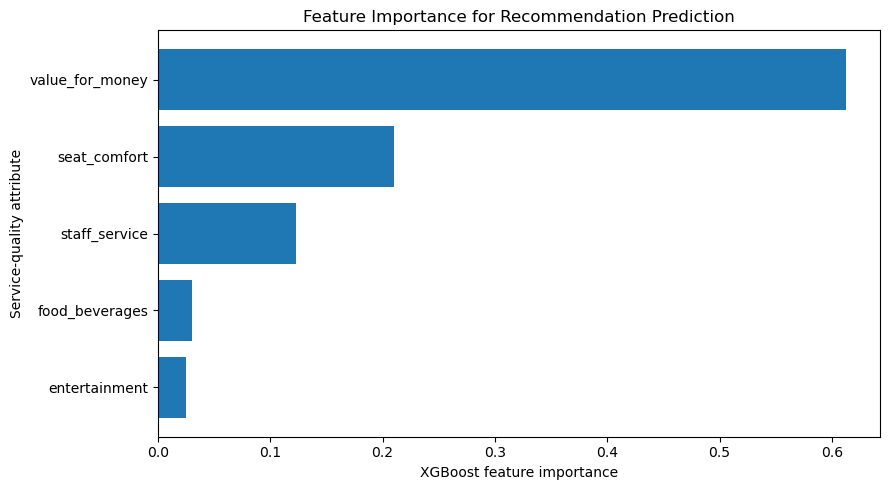

In [8]:
xgb_service_model = fitted_service_models["XGBoost"]

correlation_with_target = (
    reviews_df[structured_features + ["target"]]
    .corr(numeric_only=True)["target"]
    .drop("target")
)

association_table = pd.DataFrame({
    "Feature": structured_features,
    "Correlation with recommendation": [
        correlation_with_target[feature]
        for feature in structured_features
    ],
    "XGBoost feature importance": xgb_service_model.feature_importances_
}).sort_values(
    "XGBoost feature importance",
    ascending=False
)

display(association_table.round(6))

association_table.to_csv(
    OUTPUT_DIR / "service_attribute_association_and_importance.csv",
    index=False
)

plt.figure(figsize=(9, 5))
plt.barh(
    association_table["Feature"][::-1],
    association_table["XGBoost feature importance"][::-1]
)
plt.xlabel("XGBoost feature importance")
plt.ylabel("Service-quality attribute")
plt.title("Feature Importance for Recommendation Prediction")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "service_attribute_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 6. Text and sentiment feature analysis

VADER is applied to the original review text. TF-IDF is fitted to the cleaned text. The enhanced model contains the same five service-quality variables together with sentiment, review-length, punctuation and TF-IDF features.


In [9]:
sentiment_analyser = SentimentIntensityAnalyzer()

reviews_df["sentiment_score"] = reviews_df["review_text"].apply(
    lambda text: sentiment_analyser.polarity_scores(text)["compound"]
)

reviews_df["word_count"] = (
    reviews_df["clean_review"]
    .str.split()
    .str.len()
)

reviews_df["char_count"] = reviews_df["review_text"].str.len()
reviews_df["exclamation_count"] = reviews_df["review_text"].str.count("!")
reviews_df["question_count"] = reviews_df["review_text"].str.count(r"\?")

text_numeric_features = [
    "sentiment_score",
    "word_count",
    "char_count",
    "exclamation_count",
    "question_count"
]

display(
    reviews_df[
        [
            "review_text",
            "sentiment_score",
            "word_count",
            "exclamation_count",
            "question_count"
        ]
    ].head()
)


In [10]:
comparison_columns = (
    structured_features
    + text_numeric_features
    + ["clean_review", "target"]
)

comparison_df = reviews_df[comparison_columns].copy()
train_df = comparison_df.loc[train_index].copy()
test_df = comparison_df.loc[test_index].copy()

y_train = train_df["target"]
y_test = test_df["target"]

structured_imputer = SimpleImputer(strategy="median")
X_train_structured = structured_imputer.fit_transform(
    train_df[structured_features]
)
X_test_structured = structured_imputer.transform(
    test_df[structured_features]
)

text_imputer = SimpleImputer(strategy="median")
X_train_text_numbers = text_imputer.fit_transform(
    train_df[text_numeric_features]
)
X_test_text_numbers = text_imputer.transform(
    test_df[text_numeric_features]
)

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3
)

X_train_tfidf = tfidf.fit_transform(train_df["clean_review"])
X_test_tfidf = tfidf.transform(test_df["clean_review"])

X_train_baseline = csr_matrix(X_train_structured)
X_test_baseline = csr_matrix(X_test_structured)

X_train_enhanced = hstack([
    csr_matrix(X_train_structured),
    csr_matrix(X_train_text_numbers),
    X_train_tfidf
]).tocsr()

X_test_enhanced = hstack([
    csr_matrix(X_test_structured),
    csr_matrix(X_test_text_numbers),
    X_test_tfidf
]).tocsr()

print("Structured-only matrix:", X_train_baseline.shape)
print("AI-enhanced matrix:", X_train_enhanced.shape)


Structured-only matrix: (6044, 5)
AI-enhanced matrix: (6044, 5010)


In [11]:
comparison_parameters = {
    "n_estimators": 150,
    "max_depth": 4,
    "learning_rate": 0.10,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

baseline_model = XGBClassifier(**comparison_parameters)
enhanced_model = XGBClassifier(**comparison_parameters)

baseline_model.fit(X_train_baseline, y_train)
enhanced_model.fit(X_train_enhanced, y_train)

baseline_probability = baseline_model.predict_proba(
    X_test_baseline
)[:, 1]

enhanced_probability = enhanced_model.predict_proba(
    X_test_enhanced
)[:, 1]

baseline_prediction = (
    baseline_probability >= THRESHOLD
).astype(int)

enhanced_prediction = (
    enhanced_probability >= THRESHOLD
).astype(int)

comparison_results = pd.DataFrame([
    {
        "Model": "Structured-only",
        **model_metrics(
            y_test,
            baseline_prediction,
            baseline_probability
        )
    },
    {
        "Model": "AI-enhanced",
        **model_metrics(
            y_test,
            enhanced_prediction,
            enhanced_probability
        )
    }
])

display(comparison_results.round(6))

comparison_results.to_csv(
    OUTPUT_DIR / "structured_vs_ai_enhanced_results.csv",
    index=False
)

performance_difference = pd.DataFrame({
    "Metric": ["Accuracy", "F1 Score", "ROC AUC", "Log Loss", "Errors"],
    "AI-enhanced minus structured-only": [
        comparison_results.loc[1, "Accuracy"]
        - comparison_results.loc[0, "Accuracy"],
        comparison_results.loc[1, "F1 Score"]
        - comparison_results.loc[0, "F1 Score"],
        comparison_results.loc[1, "ROC AUC"]
        - comparison_results.loc[0, "ROC AUC"],
        comparison_results.loc[1, "Log Loss"]
        - comparison_results.loc[0, "Log Loss"],
        comparison_results.loc[1, "Errors"]
        - comparison_results.loc[0, "Errors"]
    ]
})

display(performance_difference.round(6))


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Log Loss,Errors
0,Structured-only,0.915950,0.910112,0.888715,0.899286,0.969183,0.218931,127
1,AI-enhanced,0.933157,0.928230,0.912226,0.920158,0.980863,0.171198,101


,Metric,AI-enhanced minus structured-only
0,Accuracy,0.017207
1,F1 Score,0.020872
2,ROC AUC,0.011680
3,Log Loss,-0.047733
4,Errors,-26.000000


In [12]:
print("AI-enhanced classification report:")
print(
    classification_report(
        y_test,
        enhanced_prediction,
        zero_division=0
    )
)

enhanced_confusion = pd.DataFrame(
    confusion_matrix(y_test, enhanced_prediction),
    index=[
        "Actual: non-recommended",
        "Actual: recommended"
    ],
    columns=[
        "Predicted: non-recommended",
        "Predicted: recommended"
    ]
)

print("AI-enhanced confusion matrix:")
display(enhanced_confusion)

enhanced_confusion.to_csv(
    OUTPUT_DIR / "ai_enhanced_confusion_matrix.csv"
)


AI-enhanced classification report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.94       873
           1       0.93      0.91      0.92       638

    accuracy                           0.93      1511
   macro avg       0.93      0.93      0.93      1511
weighted avg       0.93      0.93      0.93      1511

AI-enhanced confusion matrix:


,Predicted: non-recommended,Predicted: recommended
Actual: non-recommended,828,45
Actual: recommended,56,582


## 7. Repeated cross-validation

The fixed split remains the main analysis. Repeated stratified five-fold cross-validation, repeated twice, checks whether the model comparison remains stable across ten internal validation folds.


In [13]:
X_full = comparison_df[
    structured_features
    + text_numeric_features
    + ["clean_review"]
]

y_full = comparison_df["target"]

structured_preparation = ColumnTransformer([
    (
        "structured",
        SimpleImputer(strategy="median"),
        structured_features
    )
])

enhanced_preparation = ColumnTransformer([
    (
        "structured",
        SimpleImputer(strategy="median"),
        structured_features
    ),
    (
        "text_numbers",
        SimpleImputer(strategy="median"),
        text_numeric_features
    ),
    (
        "tfidf",
        TfidfVectorizer(
            stop_words="english",
            max_features=5000,
            ngram_range=(1, 2),
            min_df=3
        ),
        "clean_review"
    )
], sparse_threshold=1.0)

repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=RANDOM_STATE
)

validation_folds = list(repeated_cv.split(X_full, y_full))

scoring = {
    "Accuracy": "accuracy",
    "F1 Score": "f1",
    "ROC AUC": "roc_auc",
    "Log Loss": "neg_log_loss"
}

def run_cross_validation(model_name, preparation):
    pipeline = Pipeline([
        ("preparation", preparation),
        ("model", XGBClassifier(**comparison_parameters))
    ])

    scores = cross_validate(
        pipeline,
        X_full,
        y_full,
        cv=validation_folds,
        scoring=scoring,
        n_jobs=1
    )

    return {
        "Model": model_name,
        "Accuracy Mean": scores["test_Accuracy"].mean(),
        "Accuracy SD": scores["test_Accuracy"].std(),
        "F1 Mean": scores["test_F1 Score"].mean(),
        "F1 SD": scores["test_F1 Score"].std(),
        "ROC AUC Mean": scores["test_ROC AUC"].mean(),
        "ROC AUC SD": scores["test_ROC AUC"].std(),
        "Log Loss Mean": -scores["test_Log Loss"].mean(),
        "Log Loss SD": scores["test_Log Loss"].std()
    }

cross_validation_summary = pd.DataFrame([
    run_cross_validation(
        "Structured-only",
        structured_preparation
    ),
    run_cross_validation(
        "AI-enhanced",
        enhanced_preparation
    )
])

display(cross_validation_summary.round(6))

cross_validation_summary.to_csv(
    OUTPUT_DIR / "repeated_cross_validation_results.csv",
    index=False
)

cross_validation_table = pd.DataFrame({
    "Model": cross_validation_summary["Model"],
    "Accuracy (mean ± SD)": [
        f"{mean * 100:.2f}% ± {sd * 100:.2f}"
        for mean, sd in zip(
            cross_validation_summary["Accuracy Mean"],
            cross_validation_summary["Accuracy SD"]
        )
    ],
    "F1-score (mean ± SD)": [
        f"{mean * 100:.2f}% ± {sd * 100:.2f}"
        for mean, sd in zip(
            cross_validation_summary["F1 Mean"],
            cross_validation_summary["F1 SD"]
        )
    ],
    "ROC-AUC (mean ± SD)": [
        f"{mean:.4f} ± {sd:.4f}"
        for mean, sd in zip(
            cross_validation_summary["ROC AUC Mean"],
            cross_validation_summary["ROC AUC SD"]
        )
    ],
    "Log loss (mean ± SD)": [
        f"{mean:.4f} ± {sd:.4f}"
        for mean, sd in zip(
            cross_validation_summary["Log Loss Mean"],
            cross_validation_summary["Log Loss SD"]
        )
    ]
})

print("Cross-validation summary:")
display(cross_validation_table)


,Model,Accuracy Mean,Accuracy SD,F1 Mean,F1 SD,ROC AUC Mean,ROC AUC SD,Log Loss Mean,Log Loss SD
0,Structured-only,0.920582,0.004309,0.904937,0.005219,0.974047,0.003539,0.200698,0.012580
1,AI-enhanced,0.935076,0.005453,0.922176,0.006776,0.982113,0.002095,0.166087,0.009875


Cross-validation summary:


,Model,Accuracy (mean ± SD),F1-score (mean ± SD),ROC-AUC (mean ± SD),Log loss (mean ± SD)
0,Structured-only,92.06% ± 0.43,90.49% ± 0.52,0.9740 ± 0.0035,0.2007 ± 0.0126
1,AI-enhanced,93.51% ± 0.55,92.22% ± 0.68,0.9821 ± 0.0021,0.1661 ± 0.0099


## 8. Review publication trends

The dates are review publication dates and may not be the actual travel dates. The first and last years are partial years, so the results are interpreted descriptively.


Review publication period: 2015-03-04 to 2026-04-10
Annual results:


,year,review_count,recommendation_rate,average_sentiment,average_rating
0,2015,363,59.504,0.314,6.036
1,2016,433,69.284,0.473,6.596
2,2017,654,51.070,0.289,5.569
3,2018,737,43.962,0.202,5.056
4,2019,1084,43.450,0.151,4.906
5,2020,488,46.107,0.168,5.152
6,2021,444,43.919,0.090,4.851
7,2022,1041,34.198,-0.009,4.177
8,2023,1034,30.368,-0.049,3.898
9,2024,765,31.242,-0.083,3.856


Results by broader period:


,period,review_count,recommendation_rate,average_sentiment,average_rating
0,2015-2019,3271,50.290,0.251,5.421
1,2020-2022,1973,39.331,0.057,4.570
2,2023-April 2026,2311,33.276,-0.032,4.057


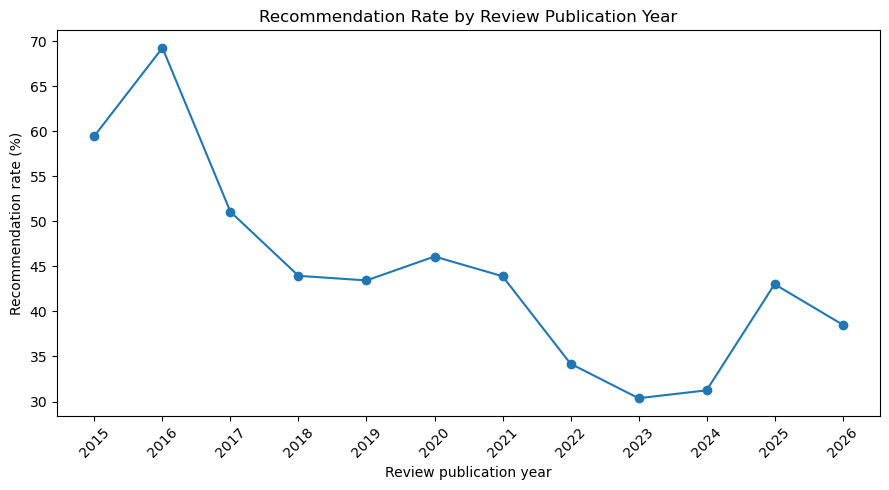

In [14]:
date_text = (
    reviews_df["date"]
    .astype(str)
    .str.replace(
        r"(\d+)(st|nd|rd|th)",
        r"\1",
        regex=True
    )
)

reviews_df["review_date"] = pd.to_datetime(
    date_text,
    format="%d %B %Y",
    errors="coerce"
)

temporal_df = reviews_df.dropna(
    subset=["review_date"]
).copy()

temporal_df["year"] = temporal_df["review_date"].dt.year

print(
    "Review publication period:",
    temporal_df["review_date"].min().date(),
    "to",
    temporal_df["review_date"].max().date()
)

year_summary = (
    temporal_df
    .groupby("year")
    .agg(
        review_count=("review_text", "count"),
        recommendation_rate=("target", "mean"),
        average_sentiment=("sentiment_score", "mean"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

year_summary["recommendation_rate"] *= 100

temporal_df["period"] = pd.cut(
    temporal_df["year"],
    bins=[2014, 2019, 2022, 2026],
    labels=[
        "2015-2019",
        "2020-2022",
        "2023-April 2026"
    ]
)

period_summary = (
    temporal_df
    .groupby("period", observed=True)
    .agg(
        review_count=("review_text", "count"),
        recommendation_rate=("target", "mean"),
        average_sentiment=("sentiment_score", "mean"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

period_summary["recommendation_rate"] *= 100

print("Annual results:")
display(year_summary.round(3))

print("Results by broader period:")
display(period_summary.round(3))

period_summary.to_csv(
    OUTPUT_DIR / "customer_temporal_results_by_period.csv",
    index=False
)

plt.figure(figsize=(9, 5))
plt.plot(
    year_summary["year"],
    year_summary["recommendation_rate"],
    marker="o"
)
plt.xlabel("Review publication year")
plt.ylabel("Recommendation rate (%)")
plt.title("Recommendation Rate by Review Publication Year")
plt.xticks(year_summary["year"], rotation=45)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "customer_recommendation_rate_by_year.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 9. Customer results by airline

These summaries describe the five airlines in the customer-review dataset. They are not directly compared with the U.S. BTS carriers.


,airline,average_sentiment,average_rating,recommendation_rate,review_count
0,qatar-airways,0.4981,7.06,71.35,1979
1,emirates,0.1228,4.91,43.02,1446
2,british-airways,0.0626,4.12,32.80,1890
3,air-india,-0.1643,3.35,26.78,1150
4,lufthansa,-0.2144,3.13,20.92,1090


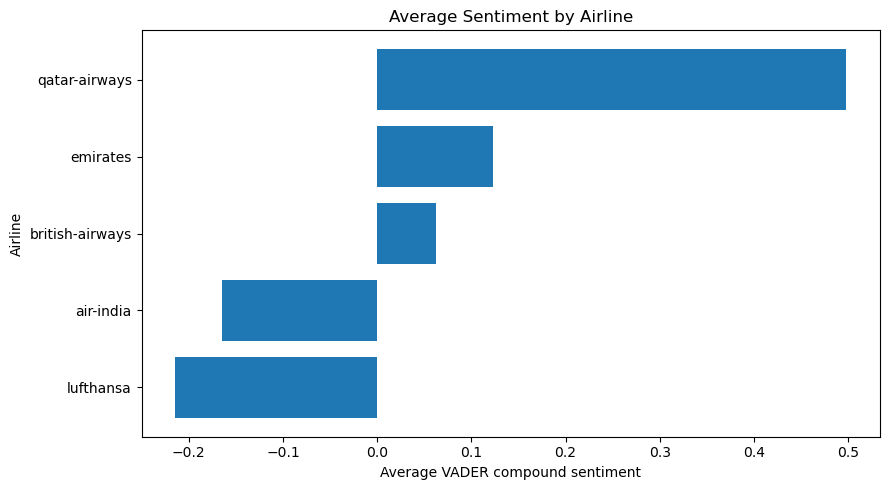

In [15]:
airline_summary = (
    reviews_df
    .groupby("airline")
    .agg(
        average_sentiment=("sentiment_score", "mean"),
        average_rating=("rating", "mean"),
        recommendation_rate=("target", "mean"),
        review_count=("review_text", "count")
    )
    .reset_index()
)

airline_summary["recommendation_rate"] *= 100

airline_summary = (
    airline_summary
    .sort_values("recommendation_rate", ascending=False)
    .reset_index(drop=True)
)

display(
    airline_summary.round({
        "average_sentiment": 4,
        "average_rating": 2,
        "recommendation_rate": 2
    })
)

airline_summary.to_csv(
    OUTPUT_DIR / "airline_customer_insights.csv",
    index=False
)

plt.figure(figsize=(9, 5))
plt.barh(
    airline_summary["airline"][::-1],
    airline_summary["average_sentiment"][::-1]
)
plt.xlabel("Average VADER compound sentiment")
plt.ylabel("Airline")
plt.title("Average Sentiment by Airline")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "average_sentiment_by_airline.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 10. Operational performance analysis

The BTS data are analysed independently. Delay measures use completed, non-diverted flights. Arrival delay rate is based on the BTS `ArrDel15` indicator, while scheduled flight volume is calculated from the full November 2025 dataset.


In [16]:
numeric_bts_columns = [
    "DepDelay",
    "DepDel15",
    "ArrDelay",
    "ArrDel15",
    "Cancelled",
    "Diverted",
    "Flights"
]

for column in numeric_bts_columns:
    bts_df[column] = pd.to_numeric(
        bts_df[column],
        errors="coerce"
    )

for column in [
    "Reporting_Airline",
    "IATA_CODE_Reporting_Airline"
]:
    bts_df[column] = (
        bts_df[column]
        .astype("string")
        .str.strip()
    )

raw_bts_dates = (
    bts_df["FlightDate"]
    .astype("string")
    .str.strip()
    .str.split()
    .str[0]
    .str.replace("/", "-", regex=False)
)

bts_df["flight_date"] = pd.to_datetime(
    raw_bts_dates,
    format="%d-%m-%Y",
    errors="raise"
)

valid_bts_dates = bts_df["flight_date"].dropna()

print(
    "BTS period:",
    valid_bts_dates.min().date(),
    "to",
    valid_bts_dates.max().date()
)
print("BTS records:", len(bts_df))

if len(bts_df) != 570550:
    raise ValueError(
        "BTS row count differs from the expected 570,550 records."
    )

if (
    valid_bts_dates.min() != pd.Timestamp("2025-11-01")
    or valid_bts_dates.max() != pd.Timestamp("2025-11-30")
):
    raise ValueError(
        "BTS dates do not cover 1-30 November 2025."
    )


BTS period: 2025-11-01 to 2025-11-30
BTS records: 570550


In [17]:
carrier_column = "IATA_CODE_Reporting_Airline"

completed_flights = bts_df.loc[
    (bts_df["Cancelled"] == 0)
    & (bts_df["Diverted"] == 0)
].copy()

delay_kpis = (
    completed_flights
    .groupby(carrier_column)
    .agg(
        average_arrival_delay=("ArrDelay", "mean"),
        average_departure_delay=("DepDelay", "mean"),
        delay_rate=("ArrDel15", "mean")
    )
    .reset_index()
)

volume_kpis = (
    bts_df
    .groupby(carrier_column)
    .agg(
        scheduled_flight_volume=("Flights", "sum")
    )
    .reset_index()
)

carrier_kpi = (
    delay_kpis
    .merge(volume_kpis, on=carrier_column, how="left")
    .rename(columns={carrier_column: "airline_code"})
)

carrier_kpi["delay_rate_percent"] = (
    carrier_kpi["delay_rate"] * 100
)

carrier_kpi = carrier_kpi.drop(columns="delay_rate")

carrier_kpi[
    [
        "average_arrival_delay",
        "average_departure_delay",
        "delay_rate_percent"
    ]
] = carrier_kpi[
    [
        "average_arrival_delay",
        "average_departure_delay",
        "delay_rate_percent"
    ]
].round(2)

carrier_kpi["scheduled_flight_volume"] = (
    carrier_kpi["scheduled_flight_volume"]
    .fillna(0)
    .round()
    .astype(int)
)

carrier_kpi = (
    carrier_kpi
    .sort_values("delay_rate_percent", ascending=False)
    .reset_index(drop=True)
)

display(carrier_kpi)

carrier_kpi.to_csv(
    OUTPUT_DIR / "BTS_carrier_operational_KPIs.csv",
    index=False
)


,airline_code,average_arrival_delay,average_departure_delay,scheduled_flight_volume,delay_rate_percent
0,OH,13.20,17.96,19746,24.92
1,B6,11.01,14.87,19818,24.91
2,F9,10.91,15.12,17047,24.10
3,AA,9.99,15.91,78826,23.47
4,YX,7.77,10.54,29356,23.47
5,G4,9.93,11.12,9652,23.02
6,NK,7.29,13.32,11793,21.41
7,UA,7.64,11.97,66691,20.69
8,WN,4.53,11.92,113938,20.16
9,AS,0.35,4.83,19752,18.81


## 11. Airline code and Airline name
| Airline code | Airline name                        |
|--------------|-------------------------------------|
| OH           | PSA Airlines                        |
| B6           | JetBlue Airways                     |
| F9           | Frontier Airlines                   |
| AA           | American Airlines                   |
| YX           | Republic Airways / Republic Airline |
| G4           | Allegiant Air                       |
| NK           | Spirit Airlines                     |
| UA           | United Airlines                     |
| WN           | Southwest Airlines                  |
| AS           | Alaska Airlines                     |
| HA           | Hawaiian Airlines                   |
| OO           | SkyWest Airlines                    |
| MQ           | Envoy Air                           |
| DL           | Delta Air Lines                     |

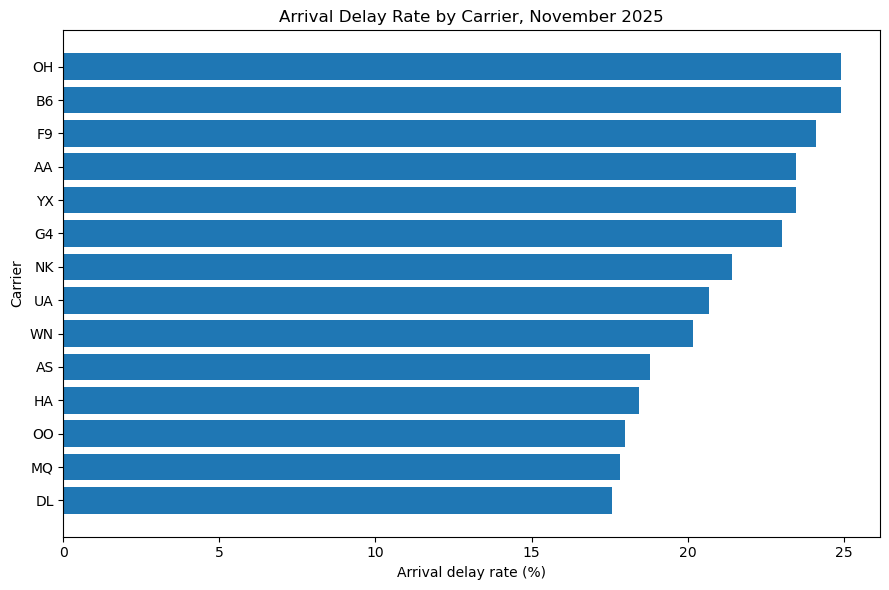

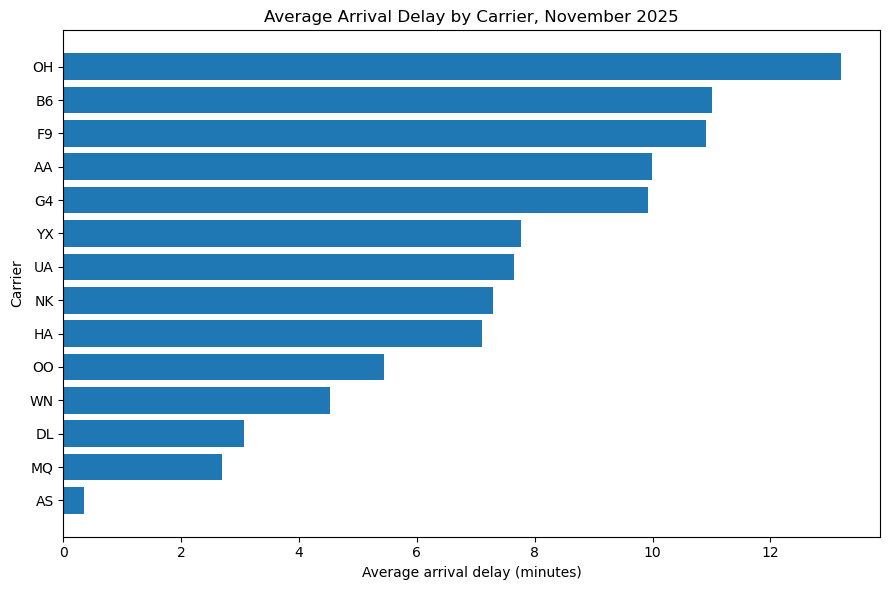

In [18]:
plt.figure(figsize=(9, 6))
plt.barh(
    carrier_kpi["airline_code"],
    carrier_kpi["delay_rate_percent"]
)
plt.xlabel("Arrival delay rate (%)")
plt.ylabel("Carrier")
plt.title("Arrival Delay Rate by Carrier, November 2025")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "BTS_delay_rate_by_carrier.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

arrival_delay_chart = carrier_kpi.sort_values(
    "average_arrival_delay",
    ascending=False
)

plt.figure(figsize=(9, 6))
plt.barh(
    arrival_delay_chart["airline_code"],
    arrival_delay_chart["average_arrival_delay"]
)
plt.xlabel("Average arrival delay (minutes)")
plt.ylabel("Carrier")
plt.title("Average Arrival Delay by Carrier, November 2025")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "BTS_average_arrival_delay_by_carrier.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 12. Main managerial findings

- Value for money has the strongest association and predictive importance among the selected service-quality attributes.
- Seat comfort and staff service also contribute meaningfully to recommendation prediction.
- Sentiment and textual features improve prediction beyond structured service ratings.
- Average arrival delay, average departure delay, delay rate and flight volume provide different operational perspectives.
- Customer-review and BTS findings are complementary and do not establish passenger-level or causal relationships.
- The findings support service-quality prioritisation, customer-feedback monitoring, disruption communication and multi-indicator operational dashboards.
